In [1]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

sys.path.insert(0, str(PROJECT_DIR))

from src.soil_water_balance import (
    SoilConfig,
    SoilWaterBalance
)

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Soil-Water Balance module imported!")

Project directory: D:\Documents\artificial_intelligence\Smart_Irrigation
Soil-Water Balance module imported!


In [2]:
df = pd.read_csv(
    DATA_DIR / "weather_with_et0.csv",
    parse_dates=["time"]
)

df = df.sort_values("time").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())

assert "et0" in df.columns
assert len(df) == 918

display(df.head())

Dataset shape: (918, 12)
Available columns: ['time', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'precipitation_sum', 'wind_speed_10m_mean', 'shortwave_radiation_sum', 'relative_humidity_2m', 'day_of_year', 'et0', 'year', 'season_day']


,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,wind_speed_10m_mean,shortwave_radiation_sum,relative_humidity_2m,day_of_year,et0,year,season_day
0,2020-05-01,23.0,8.9,16.0,0.0,1.58,25.27,64.833333,122,4.176293,2020,1
1,2020-05-02,21.2,12.4,16.3,3.5,1.96,17.02,71.041667,123,3.248464,2020,2
2,2020-05-03,22.6,11.7,16.2,4.9,3.59,18.96,72.416667,124,3.882313,2020,3
3,2020-05-04,23.8,11.5,17.7,0.0,2.66,25.66,58.708333,125,4.789880,2020,4
4,2020-05-05,20.5,10.4,15.4,0.1,2.66,19.21,64.916667,126,3.644162,2020,5


In [3]:
# ==========================================
# Threshold-Based Irrigation Simulation
# ==========================================

config = SoilConfig(
    root_depth_m=0.5,
    field_capacity=0.30,
    wilting_point=0.15,
    saturation=0.45,
    initial_moisture=0.27,
    crop_coefficient=1.0
)

soil = SoilWaterBalance(config)

IRRIGATION_THRESHOLD = 0.25
IRRIGATION_AMOUNT = 8.0

results = []
previous_year = None

for _, row in df.iterrows():

    current_year = row["time"].year

    # Reset soil state at the start of each growing season
    if current_year != previous_year:
        soil.reset()
        previous_year = current_year

    moisture_before = soil.get_soil_moisture()

    # Threshold-based irrigation decision
    irrigation = (
        IRRIGATION_AMOUNT
        if moisture_before < IRRIGATION_THRESHOLD
        else 0.0
    )

    # Simulate one day
    result = soil.step(
        rainfall=float(row["precipitation_sum"]),
        irrigation=irrigation,
        et0=float(row["et0"])
    )

    results.append({
        "time": row["time"],
        "year": current_year,
        "moisture_before": moisture_before,
        **result
    })

simulation_df = pd.DataFrame(results)

print("Simulation completed!")
print("Total simulated days:", len(simulation_df))

display(simulation_df.head())

Simulation completed!
Total simulated days: 918


,time,year,moisture_before,soil_moisture,water_storage_mm,rainfall_mm,irrigation_mm,etc_demand_mm,actual_et_mm,drainage_mm,runoff_mm,stress_factor,balance_error_mm
0,2020-05-01,2020,0.270000,0.263318,131.658966,0.0,0.0,4.176293,3.341034,0.0,0.0,0.800000,0.0
1,2020-05-02,2020,0.263318,0.265107,132.553309,3.5,0.0,3.248464,2.605656,0.0,0.0,0.802120,0.0
2,2020-05-03,2020,0.265107,0.268441,134.220465,4.9,0.0,3.882313,3.232844,0.0,0.0,0.832711,0.0
3,2020-05-04,2020,0.268441,0.260877,130.438346,0.0,0.0,4.789880,3.782119,0.0,0.0,0.789606,0.0
4,2020-05-05,2020,0.260877,0.255680,127.839804,0.1,0.0,3.644162,2.698543,0.0,0.0,0.740511,0.0


In [4]:
# ==========================================
# Irrigation Performance Metrics
# ==========================================

total_irrigation = simulation_df["irrigation_mm"].sum()
total_rainfall = simulation_df["rainfall_mm"].sum()
total_drainage = simulation_df["drainage_mm"].sum()
total_runoff = simulation_df["runoff_mm"].sum()

average_moisture = simulation_df["soil_moisture"].mean()

optimal_days = simulation_df[
    simulation_df["soil_moisture"].between(0.25, 0.30)
]

optimal_percentage = (
    len(optimal_days) / len(simulation_df) * 100
)

print("THRESHOLD IRRIGATION RESULTS")
print("=" * 45)

print(f"Total irrigation: {total_irrigation:.2f} mm")
print(f"Total rainfall: {total_rainfall:.2f} mm")
print(f"Total drainage: {total_drainage:.2f} mm")
print(f"Total runoff: {total_runoff:.2f} mm")
print(f"Average soil moisture: {average_moisture:.3f}")
print(f"Days in target range: {optimal_percentage:.2f}%")
print(
    "Maximum balance error:",
    simulation_df["balance_error_mm"].abs().max()
)

THRESHOLD IRRIGATION RESULTS
Total irrigation: 2392.00 mm
Total rainfall: 1335.30 mm
Total drainage: 199.36 mm
Total runoff: 0.00 mm
Average soil moisture: 0.258
Days in target range: 67.43%
Maximum balance error: 2.842170943040401e-14


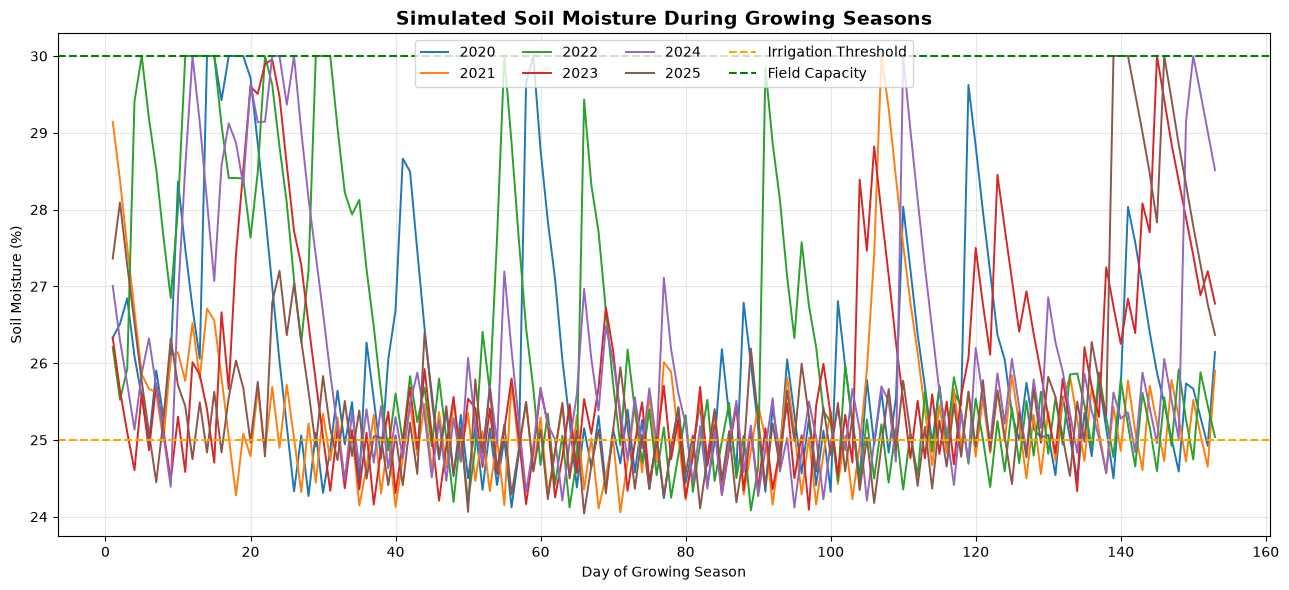

In [5]:
# ==========================================
# Soil Moisture Visualization
# ==========================================

fig, ax = plt.subplots(figsize=(13, 6))

for year, group in simulation_df.groupby("year"):
    ax.plot(
        range(1, len(group) + 1),
        group["soil_moisture"] * 100,
        label=str(year),
        linewidth=1.4
    )

ax.axhline(
    25,
    linestyle="--",
    color="orange",
    label="Irrigation Threshold"
)

ax.axhline(
    30,
    linestyle="--",
    color="green",
    label="Field Capacity"
)

ax.set_title(
    "Simulated Soil Moisture During Growing Seasons",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Day of Growing Season")
ax.set_ylabel("Soil Moisture (%)")

ax.legend(ncol=4)
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "soil_moisture_seasons.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
output_file = DATA_DIR / "soil_simulation_results.csv"

simulation_df.to_csv(output_file, index=False)

assert len(simulation_df) == len(df)
assert simulation_df["balance_error_mm"].abs().max() < 1e-6

print("Soil simulation saved successfully!")
print("File:", output_file)
print("Total records:", len(simulation_df))
print("Water balance validation: PASSED")

Soil simulation saved successfully!
File: D:\Documents\artificial_intelligence\Smart_Irrigation\data\soil_simulation_results.csv
Total records: 918
Water balance validation: PASSED


In [7]:
# ==========================================
# Yearly Irrigation Performance Analysis
# ==========================================

yearly_results = simulation_df.groupby("year").agg(
    irrigation_mm=("irrigation_mm", "sum"),
    rainfall_mm=("rainfall_mm", "sum"),
    drainage_mm=("drainage_mm", "sum"),
    average_moisture=("soil_moisture", "mean"),
    minimum_moisture=("soil_moisture", "min"),
    maximum_moisture=("soil_moisture", "max")
)

yearly_results["target_days_pct"] = (
    simulation_df.assign(
        in_target=simulation_df["soil_moisture"]
        .between(0.25, 0.30)
    )
    .groupby("year")["in_target"]
    .mean() * 100
)

print("YEARLY IRRIGATION PERFORMANCE")
display(yearly_results.round(3))

yearly_results.to_csv(
    RESULTS_DIR / "yearly_irrigation_performance.csv"
)

YEARLY IRRIGATION PERFORMANCE


,irrigation_mm,rainfall_mm,drainage_mm,average_moisture,minimum_moisture,maximum_moisture,target_days_pct
year,,,,,,,
2020,360.0,253.8,33.323,0.259,0.241,0.3,70.588
2021,512.0,96.0,4.125,0.253,0.241,0.3,58.170
2022,344.0,331.1,84.199,0.262,0.241,0.3,71.895
2023,376.0,226.0,11.888,0.259,0.241,0.3,69.281
2024,336.0,268.7,32.004,0.260,0.241,0.3,72.549
2025,464.0,159.7,33.820,0.255,0.240,0.3,62.092


## Week 2 — Results and Conclusions

### FAO-56 Penman–Monteith Implementation

A Python implementation of the FAO-56 Penman–Monteith equation was developed to estimate daily reference evapotranspiration (ET₀).

The model processed 918 daily weather observations covering six tomato growing seasons (May–September, 2020–2025).

The mean estimated reference evapotranspiration was approximately 5.09 mm/day.

### Soil-Water Balance Simulation

A simplified soil-water balance model was implemented to simulate daily changes in root-zone soil moisture based on precipitation, irrigation, evapotranspiration, surface runoff, and drainage.

The model uses provisional loam soil parameters, a 0.5 m root-zone depth, and a constant crop coefficient of 1.0.

Numerical water conservation checks were successfully completed.

### Baseline Irrigation Strategy

A threshold-based irrigation controller was implemented. Irrigation of 8 mm is applied whenever soil moisture falls below 25%.

Across six simulated growing seasons, the controller produced:

- Total irrigation: 2,392 mm
- Average irrigation per season: 398.7 mm
- Total rainfall: 1,335.3 mm
- Total drainage: 199.36 mm
- Average soil moisture: 25.8%
- Days within the target moisture range (25–30%): 67.43%

The highest seasonal irrigation demand occurred in 2021 (512 mm), while the lowest occurred in 2024 (336 mm).

### Limitations

The current model uses simplified soil properties and a fixed crop coefficient. Soil moisture is simulated rather than measured by physical sensors.

The FAO-56 implementation also requires independent numerical validation against published reference examples.

### Next Steps

Week 3 will focus on developing a custom Gymnasium reinforcement learning environment, defining the state and action spaces, and implementing reward functions for irrigation optimization.